# W07B · A · 편차·제곱합·F

먼저 설명 예제를 실행하고 Q43–Q52을 풉니다. 의도적 빈칸·오류는 Markdown 문제에 있고 실행 셀은 주석으로 비워 두었습니다. 모두 실행이 끝났다고 문제풀이가 완료된 것은 아닙니다. 직접 코드를 채우고 예상·출력·이유를 기록하세요.

[입력·출력 설명](https://github.com/lunalab-ai/regre/blob/2026-fall-w07b/src/review-fit-api.md) · [review_fit_data · L2](https://github.com/lunalab-ai/regre/blob/2026-fall-w07b/src/review-fit.R#L2) · [review_fit_components · L5](https://github.com/lunalab-ai/regre/blob/2026-fall-w07b/src/review-fit.R#L5) · [review_fit_intervals · L21](https://github.com/lunalab-ai/regre/blob/2026-fall-w07b/src/review-fit.R#L21)

CPU R런타임에서 단독 실행합니다. 준비 셀은 고정 태그의 소스를 다운로드하고 재실행 때 캐시 체크섬을 확인합니다. 다운로드 실패를 다른 데이터로 대체하지 않습니다.

In [ ]:
tag <- "2026-fall-w07b"
locations <- c("labs/student/w07b/data","../../labs/student/w07b/data")
found <- locations[file.exists(file.path(locations,"review-fit.R"))]
data_dir <- if(length(found)) found[1] else file.path(path.expand("~"),".cache","regre",tag)
dir.create(data_dir,recursive=TRUE,showWarnings=FALSE)
target <- file.path(data_dir,"review-fit.R")
options(timeout=120)
if(!file.exists(target)) {
 download.file(paste0("https://raw.githubusercontent.com/lunalab-ai/regre/",tag,"/src/review-fit.R"),target,mode="wb")
 cat("Downloaded fixed source\n")
} else cat("Reusing cache; verifying checksum\n")
if(unname(tools::md5sum(target))!="d8dc8b1ab2e9eaa9bf8088dd32eb8b5c") stop("Source checksum mismatch; remove only the named cached file and rerun.")
source(target)
demo <- review_fit_data()
demo_result <- review_fit_components(demo$Units,demo$Minutes)
print(demo)
cat(R.version.string,"\n")


In [ ]:
# Shared explanation example; exercise answers stay private.
components <- demo_result$rows
print(components)
print(c(SST=demo_result$SST,SSR=demo_result$SSR,SSE=demo_result$SSE,cross=demo_result$cross,R2=demo_result$R2))
intervals <- review_fit_intervals(demo$Units,demo$Minutes,c(3,5,8))
print(intervals)
plot(demo$Units,demo$Minutes,pch=19,col="#087f8c",xlab="Tasks",ylab="Minutes")
abline(demo_result$model,col="#087f8c",lwd=2)
abline(h=mean(demo$Minutes),lty=2,col="gray")
segments(demo$Units,demo$Minutes,demo$Units,components$fitted,col="#bb4c23",lwd=2)


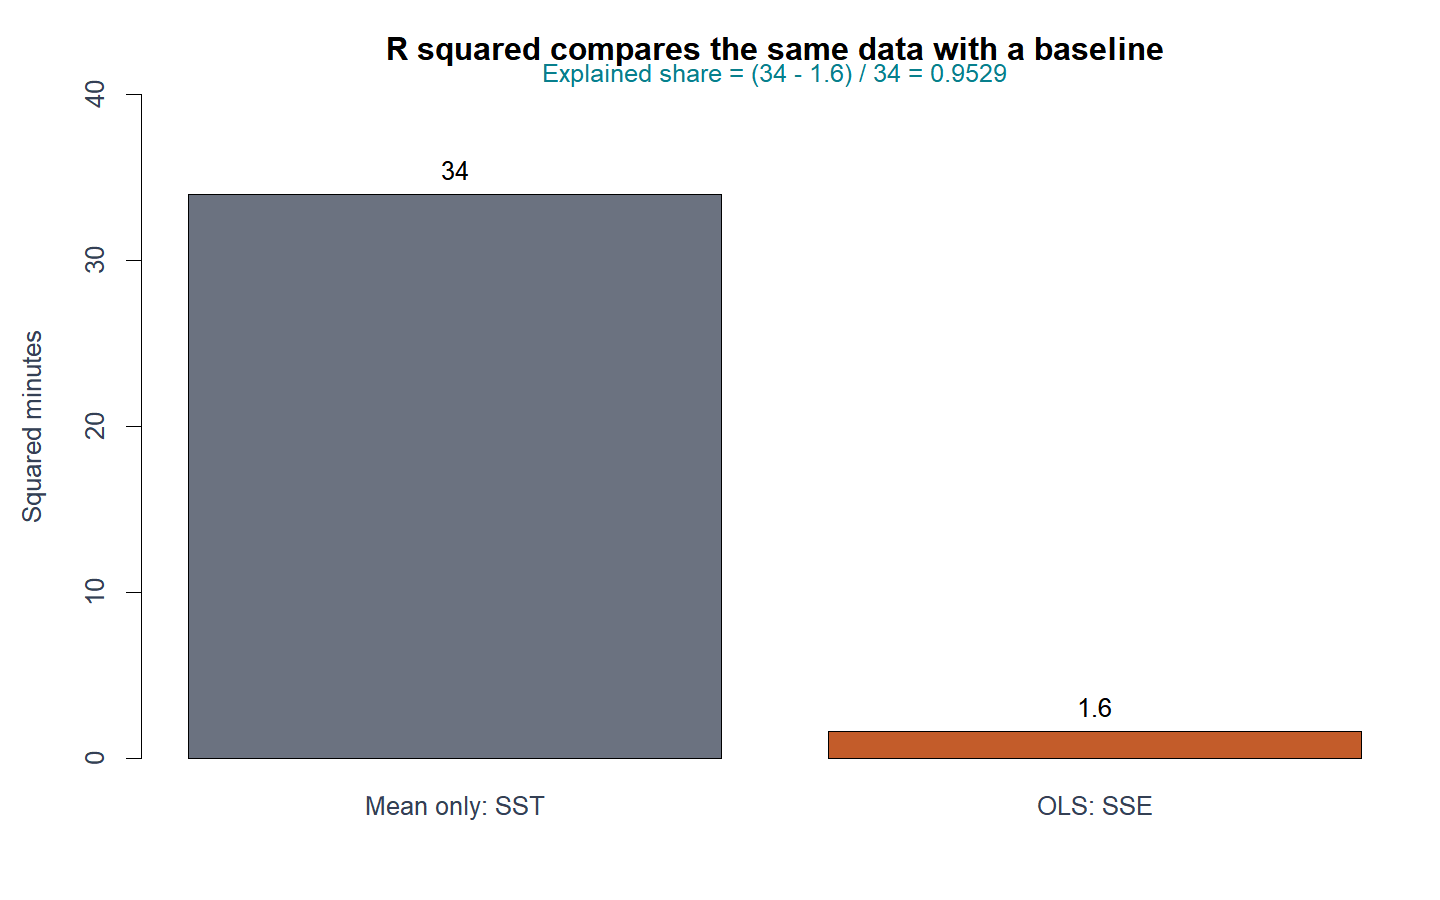

그림과 위 코드의 결과를 비교하세요. [그림 원본](https://github.com/lunalab-ai/regre/blob/2026-fall-w07b/course/notion/w07b/assets/04-r2.png)

## Q43 · 세 편차를 코드로

평균5, 적합7, 관측6이다. ____를 채워 전체·설명·잔차를 계산하시오.

```r
y <- 6; fitted_value <- 7; ybar <- 5
total <- y - ____
explained <- ____ - ybar
residual <- y - ____
print(c(total, explained, residual))
```

필요한 기본 문법: c는 벡터, mean은 평균, sum은 합, ^2는 각 원소 제곱, sqrt는 제곱근, length는 원소 수입니다. 지정한 코드의 계산 이유까지 설명하세요.

In [ ]:
# Q43 TODO: 직접 완성하고 실행하세요.

## Q44 · 합의 제곱 오류

잔차제곱합을 구하려는 코드이다. 실행은 되지만 개념적으로 잘못된 한 줄을 고치고 원래 출력과 수정 출력을 비교하시오.

```r
e <- c(-2,1,1)
SSE <- sum(e)^2
print(SSE)
```

필요한 기본 문법: c는 벡터, mean은 평균, sum은 합, ^2는 각 원소 제곱, sqrt는 제곱근, length는 원소 수입니다. 지정한 코드의 계산 이유까지 설명하세요.

In [ ]:
# Q44 TODO: 직접 완성하고 실행하세요.

## Q45 · 한 점의 부호 읽기

실행하기 전에 출력 벡터의 세 수와 부호의 의미를 적으시오.

```r
y <- 3; fitted_value <- 5; ybar <- 4
print(c(y-ybar,fitted_value-ybar,y-fitted_value))
```

필요한 기본 문법: c는 벡터, mean은 평균, sum은 합, ^2는 각 원소 제곱, sqrt는 제곱근, length는 원소 수입니다. 지정한 코드의 계산 이유까지 설명하세요.

In [ ]:
# Q45 TODO: 직접 완성하고 실행하세요.

## Q46 · 교차항 확인

a는 설명편차, e는 잔차이다. 점별 제곱합 분해에는 교차항이 필요하다. ____를 채워 합의 분해를 확인하시오.

```r
a <- c(-1,0,1); e <- c(1,-2,1)
cross <- 2*sum(____)
print(c(sum((a+e)^2),sum(a^2)+sum(e^2)+cross))
```

필요한 기본 문법: c는 벡터, mean은 평균, sum은 합, ^2는 각 원소 제곱, sqrt는 제곱근, length는 원소 수입니다. 지정한 코드의 계산 이유까지 설명하세요.

In [ ]:
# Q46 TODO: 직접 완성하고 실행하세요.

## Q47 · 기준 대비 줄어든 오차

SST=80, SSE=20이다. R²를 구하는 빈칸과 해석을 쓰시오.

```r
SST <- 80; SSE <- 20
R2 <- 1 - ____/____
print(R2)
```

필요한 기본 문법: c는 벡터, mean은 평균, sum은 합, ^2는 각 원소 제곱, sqrt는 제곱근, length는 원소 수입니다. 지정한 코드의 계산 이유까지 설명하세요.

In [ ]:
# Q47 TODO: 직접 완성하고 실행하세요.

## Q48 · SST는 무엇에서 빼는가

평균 기준 SST를 구하려 한다. 잘못된 줄을 고치고 두 값의 차이를 설명하시오.

```r
y <- c(4,6,8)
SST <- sum(y^2)
print(SST)
```

필요한 기본 문법: c는 벡터, mean은 평균, sum은 합, ^2는 각 원소 제곱, sqrt는 제곱근, length는 원소 수입니다. 지정한 코드의 계산 이유까지 설명하세요.

In [ ]:
# Q48 TODO: 직접 완성하고 실행하세요.

## Q49 · 단위 변경 출력

분을 초로 바꾸면 제곱합은60²배가 된다. 아래 두 출력값을 예상하고 이유를 쓰시오.

```r
SST <- 50; SSE <- 10
print(c(1-SSE/SST,1-(60^2*SSE)/(60^2*SST)))
```

필요한 기본 문법: c는 벡터, mean은 평균, sum은 합, ^2는 각 원소 제곱, sqrt는 제곱근, length는 원소 수입니다. 지정한 코드의 계산 이유까지 설명하세요.

In [ ]:
# Q49 TODO: 직접 완성하고 실행하세요.

## Q50 · 설명 비율을 거꾸로

절편 있는 OLS에서 SST=60, SSR=45, SSE=15이다. R²를 구하려는 코드의 의미 오류를 고치시오.

```r
SST <- 60; SSR <- 45; SSE <- 15
R2 <- 1-SSR/SST
print(R2)
```

필요한 기본 문법: c는 벡터, mean은 평균, sum은 합, ^2는 각 원소 제곱, sqrt는 제곱근, length는 원소 수입니다. 지정한 코드의 계산 이유까지 설명하세요.

In [ ]:
# Q50 TODO: 직접 완성하고 실행하세요.

## Q51 · F의 분모 자유도

절편과 기울기를 추정하는 단순회귀이다. n=9, SSR=28, SSE=14일 때 F를 완성하시오.

```r
n <- 9; SSR <- 28; SSE <- 14
df_error <- n - ____
F_value <- (SSR/1)/(SSE/df_error)
print(F_value)
```

필요한 기본 문법: c는 벡터, mean은 평균, sum은 합, ^2는 각 원소 제곱, sqrt는 제곱근, length는 원소 수입니다. 지정한 코드의 계산 이유까지 설명하세요.

In [ ]:
# Q51 TODO: 직접 완성하고 실행하세요.

## Q52 · t와 F의 연결 출력

같은 절편 있는 단순회귀에서 기울기0을 양측 검정한다. t=-2.5, 자유도8이다. pt는 t분포 누적확률, pf는 F분포 누적확률이다. 출력과 p값의 관계를 설명하시오.

```r
t_value <- -2.5; df <- 8
F_value <- t_value^2
p_t <- 2*pt(-abs(t_value),df)
p_F <- pf(F_value,1,df,lower.tail=FALSE)
print(round(c(F_value,p_t,p_F),4))
```

필요한 기본 문법: c는 벡터, mean은 평균, sum은 합, ^2는 각 원소 제곱, sqrt는 제곱근, length는 원소 수입니다. 지정한 코드의 계산 이유까지 설명하세요.

In [ ]:
# Q52 TODO: 직접 완성하고 실행하세요.

## 마지막 활동 APP01 · 입력 한 줄과 구간 폭

[누적 앱 W07B](https://lunalab-ai.github.io/regre/apps/w07b/)에서 W07B 탭을 엽니다. x0=3과5의 평균·개별 구간을 비교하세요. 먼저 무엇이 바뀔지 예상합니다. x0=8에서는 외삽 표시도 확인합니다.

[앱 편집기](https://lunalab-ai.github.io/regre/apps/w07b/edit/index.html)에서 `numericInput("w7b_x0",...)`의 `value=3`을5로 바꾸어 Run합니다. 입력이 `review_fit_intervals`의 x0로 전달되고 표·그림으로 나타나는 연결을 찾으세요. 아래 코드에서도 my_x0를 바꿔 결과를 비교합니다.



In [ ]:
my_x0 <- 3
my_intervals <- review_fit_intervals(demo$Units,demo$Minutes,my_x0)
print(my_intervals)
stopifnot(nrow(demo)==5,abs(demo_result$SSE-1.6)<1e-12,abs(demo_result$SST-34)<1e-12)